In [15]:
import os
import re
from collections import Counter
import numpy as numpy
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.sans-serif"] = "Segoe UI", "DejaVu", "Arial"
plt.rcParams["figure.titlesize"] = 14
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11

print("Libraries imported successfully!")

Libraries imported successfully!


In [16]:
data_path = os.path.join("..","data","raw","IMDB Dataset.csv")

df = pd.read_csv(data_path)
print(f"Dataset shape {df.shape[0]:,} rows, {df.shape[1]} columns\n")
print("Missing values per column:")
print(df.isnull().sum())

display(df.head(10))

Dataset shape 50,000 rows, 2 columns

Missing values per column:
review       0
sentiment    0
dtype: int64


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive
5,"Probably my all-time favorite movie, a story o...",positive
6,I sure would like to see a resurrection of a u...,positive
7,"This show was an amazing, fresh & innovative i...",negative
8,Encouraged by the positive comments about this...,negative
9,If you like original gut wrenching laughter yo...,positive


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_20576\374020751.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sentiment_counts.index, y=sentiment_counts.values, ax=ax1, palette=colors)


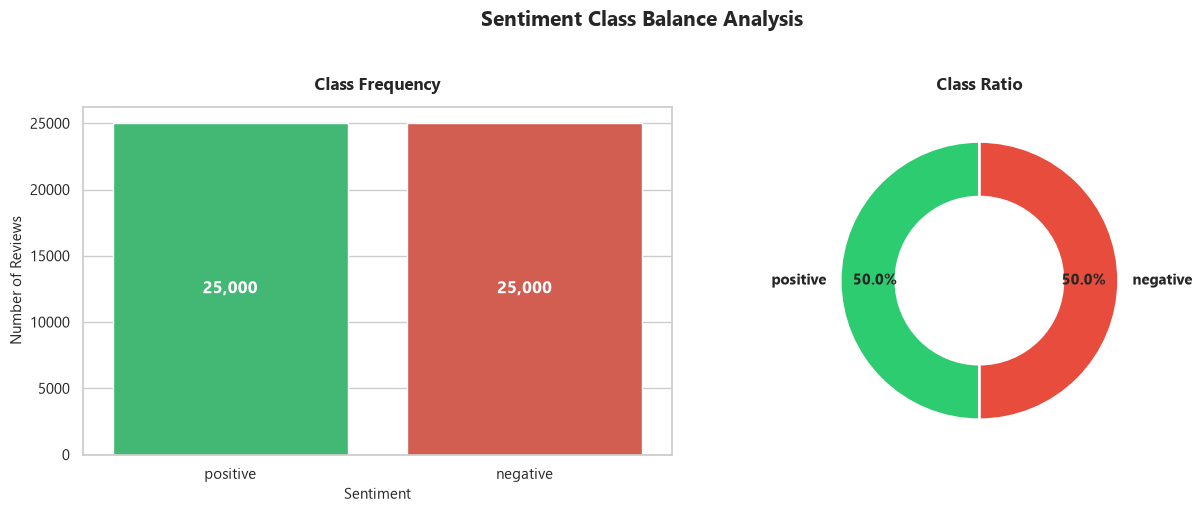

In [17]:
sentiment_counts = df['sentiment'].value_counts()
colors = ['#2ecc71', '#e74c3c']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# 1. Bar Plot
sns.barplot(x=sentiment_counts.index, y=sentiment_counts.values, ax=ax1, palette=colors)
ax1.set_title("Class Frequency", pad=12, fontweight="bold")
ax1.set_xlabel("Sentiment")
ax1.set_ylabel("Number of Reviews")
for p in ax1.patches:
    ax1.annotate(f"{int(p.get_height()):,}", 
                 (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                 ha='center', va='center', color='white', fontweight='bold', fontsize=12)

# 2. Donut Chart
ax2.pie(sentiment_counts.values, labels=sentiment_counts.index, autopct='%1.1f%%',
        startangle=90, colors=colors, pctdistance=0.75,
        textprops={'fontsize': 11, 'fontweight': 'bold'},
        wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2))
ax2.set_title("Class Ratio", pad=12, fontweight="bold")

plt.suptitle("Sentiment Class Balance Analysis", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


In [18]:
# Compute review text statistics
df['char_count'] = df['review'].apply(len)
df['word_count'] = df['review'].apply(lambda x: len(x.split()))
df['avg_word_length'] = df['char_count'] / (df['word_count'] + 1e-5)

display(df.groupby('sentiment')[['word_count', 'char_count', 'avg_word_length']].describe().T)


sentiment                  negative      positive
word_count      count  25000.000000  25000.000000
                mean     229.464560    232.849320
                std      164.947795    177.497046
                min        4.000000     10.000000
                25%      128.000000    125.000000
                50%      174.000000    172.000000
                75%      278.000000    284.000000
                max     1522.000000   2470.000000
char_count      count  25000.000000  25000.000000
                mean    1294.064360   1324.797680
                std      945.892669   1031.492627
                min       32.000000     65.000000
                25%      706.000000    691.000000
                50%      973.000000    968.000000
                75%     1567.250000   1614.000000
                max     8969.000000  13704.000000
avg_word_length count  25000.000000  25000.000000
                mean       5.617035      5.651292
                std        0.326808      0.353620
                min        4.417910      2.236486
                25%        5.402597      5.422902
                50%        5.600824      5.641396
                75%        5.813877      5.867768
                max       12.749968     13.272725

## Emoji Analysis 😊

IMDB reviews can contain emojis, which often carry sentiment. Here we check:
- How many reviews contain at least one emoji
- Which emojis are the most common

We use the `emoji` package (instead of a hand-written regex) because it stays up to date with every Unicode emoji version and correctly handles complex emojis (skin tones, ZWJ sequences like 👨‍👩‍👧‍👦).


Reviews containing emojis: 5 / 50,000 (0.01%)
Total emojis found:        5

Reviews with emojis by sentiment:
sentiment
negative    0.01
positive    0.01
Name: has_emoji, dtype: float64 



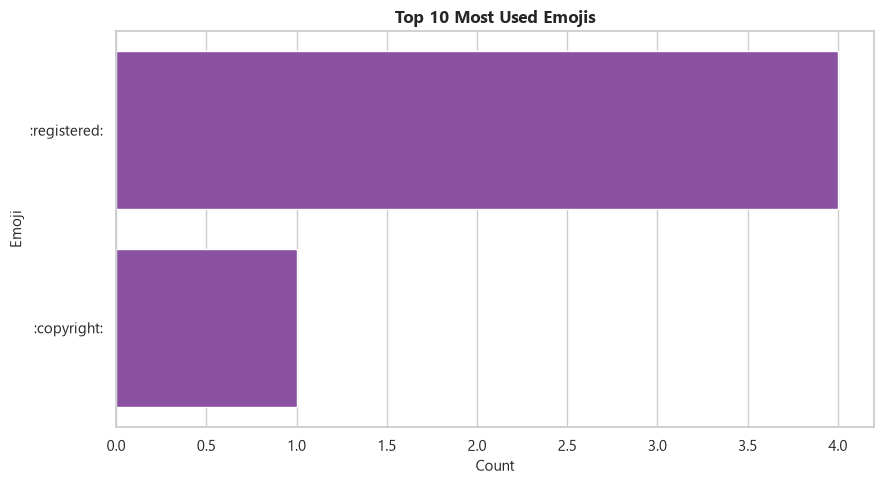

In [19]:
import emoji

# Count emojis in each review + boolean flag
df['emoji_count'] = df['review'].apply(emoji.emoji_count)
df['has_emoji']   = df['emoji_count'] > 0

n_with = df['has_emoji'].sum()
print(f"Reviews containing emojis: {n_with:,} / {len(df):,} ({n_with/len(df)*100:.2f}%)")
print(f"Total emojis found:        {df['emoji_count'].sum():,}\n")

# Percentage of reviews with emojis, per sentiment class
print("Reviews with emojis by sentiment:")
print((df.groupby('sentiment')['has_emoji'].mean() * 100).round(2), "\n")

# Top 10 most used emojis
all_emojis = Counter()
for text in df['review']:
    all_emojis.update(e['emoji'] for e in emoji.emoji_list(text))

top_emojis = pd.DataFrame(all_emojis.most_common(10), columns=['emoji', 'count'])
top_emojis['name'] = top_emojis['emoji'].apply(emoji.demojize)   # names, so plot labels always render

plt.figure(figsize=(9, 5))
sns.barplot(data=top_emojis, x='count', y='name', color='#8e44ad')
plt.title("Top 10 Most Used Emojis", fontweight="bold")
plt.xlabel("Count")
plt.ylabel("Emoji")
plt.tight_layout()
plt.show()

## Preprocessing — Three Ways to Handle Emojis

| # | Method | What it does | Example | Best for |
|---|--------|--------------|---------|----------|
| 1 | **remove** | strips emojis completely | `"loved it 😍"` → `"loved it"` | traditional ML (BoW / TF-IDF) |
| 2 | **keep** | keeps emojis as unicode chars | `"loved it 😍"` → `"loved it 😍"` | transformers (BERT, etc.) |
| 3 | **demojize** | converts emoji to text | `"loved it 😍"` → `"loved it :smiling_face_with_heart_eyes:"` | any model, keeps sentiment as text |

Set the `EMOJI_METHOD` flag below to switch between them. **No tokenization is done here** — text stays as a raw string so you can apply different tokenizers later for different algorithms.


In [21]:
# Choose one of the three emoji methods: "remove" | "keep" | "demojize"
EMOJI_METHOD = "demojize"

# Regex matching common emoji unicode blocks (only used by the "keep" method)
KEEP_PATTERN = re.compile(
    r'[^\w\s'                  # keep word chars & whitespace
    r'\U0001F000-\U0001FAFF'  # emoji & pictograph blocks
    r'\u2600-\u27BF'          # misc symbols & dingbats
    r'\u2B00-\u2BFF'          # misc symbols & arrows
    r'\uFE0F]'                # variation selector
)

def clean_text(text, method=EMOJI_METHOD):
    # ---- common cleaning (applied to all three methods) ----
    text = re.sub(r'<.*?>', ' ', text)             # remove HTML tags (<br />)
    text = re.sub(r'http\S+|www\S+', ' ', text)    # remove URLs
    text = text.lower()                            # lowercase

    # ---- emoji handling: pick ONE of the three methods ----
    if method == "remove":
        # Method 1: drop emojis completely
        text = emoji.replace_emoji(text, replace='')
        text = re.sub(r'[^a-z\s]', ' ', text)      # keep letters only

    elif method == "keep":
        # Method 2: keep emojis as unicode chars (useful for BERT-like models)
        text = KEEP_PATTERN.sub(' ', text)

    elif method == "demojize":
        # Method 3: convert emojis to text, e.g. 😍 -> :smiling_face_with_heart_eyes:
        text = emoji.demojize(text)
        text = re.sub(r'[^a-z_:\s]', ' ', text)    # keep letters, '_' and ':'

    # ---- collapse extra whitespace ----
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Quick demo: the same sentence passed through all three methods
sample = "I loved this movie 😍🔥 truly amazing 👏"
print("Original :", sample)
print("Remove   :", clean_text(sample, method="remove"))
print("Keep     :", clean_text(sample, method="keep"))
print("Demojize :", clean_text(sample, method="demojize"))

df['review'] = df['review'].apply(clean_text)

print(f"Method used: '{EMOJI_METHOD}'\n")


Original : I loved this movie 😍🔥 truly amazing 👏
Remove   : i loved this movie truly amazing
Keep     : i loved this movie 😍🔥 truly amazing 👏
Demojize : i loved this movie :smiling_face_with_heart eyes::fire: truly amazing :clapping_hands:
Method used: 'demojize'



C:\Users\Lenovo\AppData\Local\Temp\ipykernel_20576\2701246916.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='sentiment', y='word_count', palette={'positive': '#2ecc71', 'negative': '#e74c3c'}, ax=axes[0, 1])


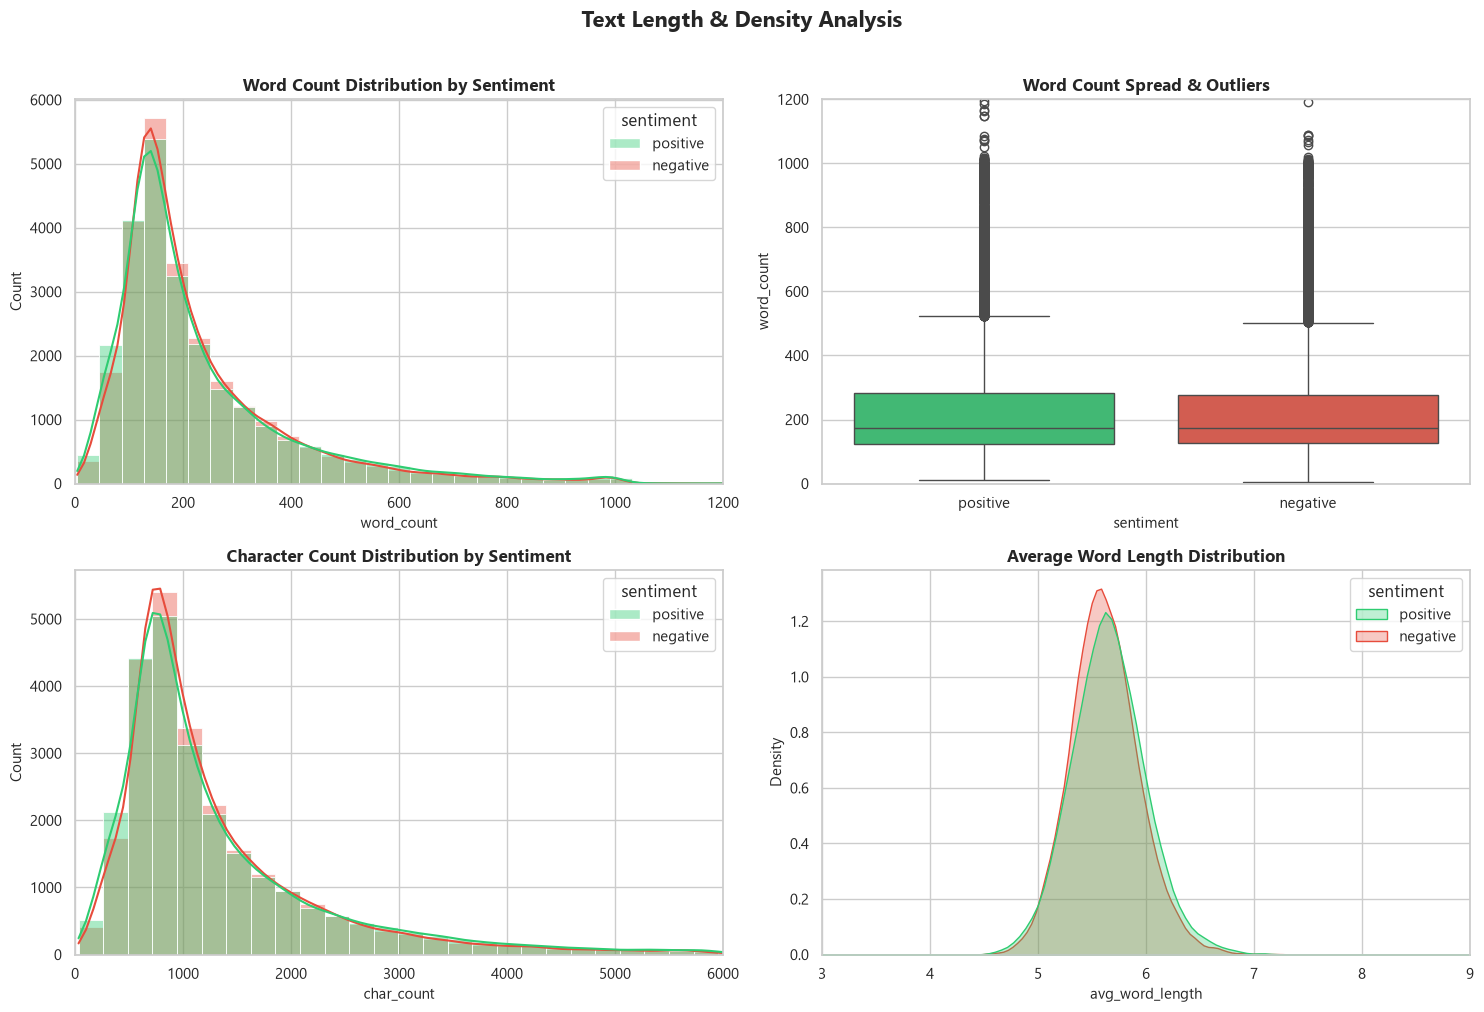

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Word Count Distribution (Histogram + KDE)
sns.histplot(data=df, x='word_count', hue='sentiment', bins=60, kde=True, 
             palette={'positive': '#2ecc71', 'negative': '#e74c3c'}, ax=axes[0, 0], alpha=0.4)
axes[0, 0].set_title("Word Count Distribution by Sentiment", fontweight="bold")
axes[0, 0].set_xlim(0, 1200)

# 2. Word Count Boxplot (Outlier analysis)
sns.boxplot(data=df, x='sentiment', y='word_count', palette={'positive': '#2ecc71', 'negative': '#e74c3c'}, ax=axes[0, 1])
axes[0, 1].set_title("Word Count Spread & Outliers", fontweight="bold")
axes[0, 1].set_ylim(0, 1200)

# 3. Character Count Distribution
sns.histplot(data=df, x='char_count', hue='sentiment', bins=60, kde=True,
             palette={'positive': '#2ecc71', 'negative': '#e74c3c'}, ax=axes[1, 0], alpha=0.4)
axes[1, 0].set_title("Character Count Distribution by Sentiment", fontweight="bold")
axes[1, 0].set_xlim(0, 6000)

# 4. Average Word Length
sns.kdeplot(data=df, x='avg_word_length', hue='sentiment', common_norm=False,
            palette={'positive': '#2ecc71', 'negative': '#e74c3c'}, ax=axes[1, 1], fill=True, alpha=0.3)
axes[1, 1].set_title("Average Word Length Distribution", fontweight="bold")
axes[1, 1].set_xlim(3, 9)

plt.suptitle("Text Length & Density Analysis", fontsize=16, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()


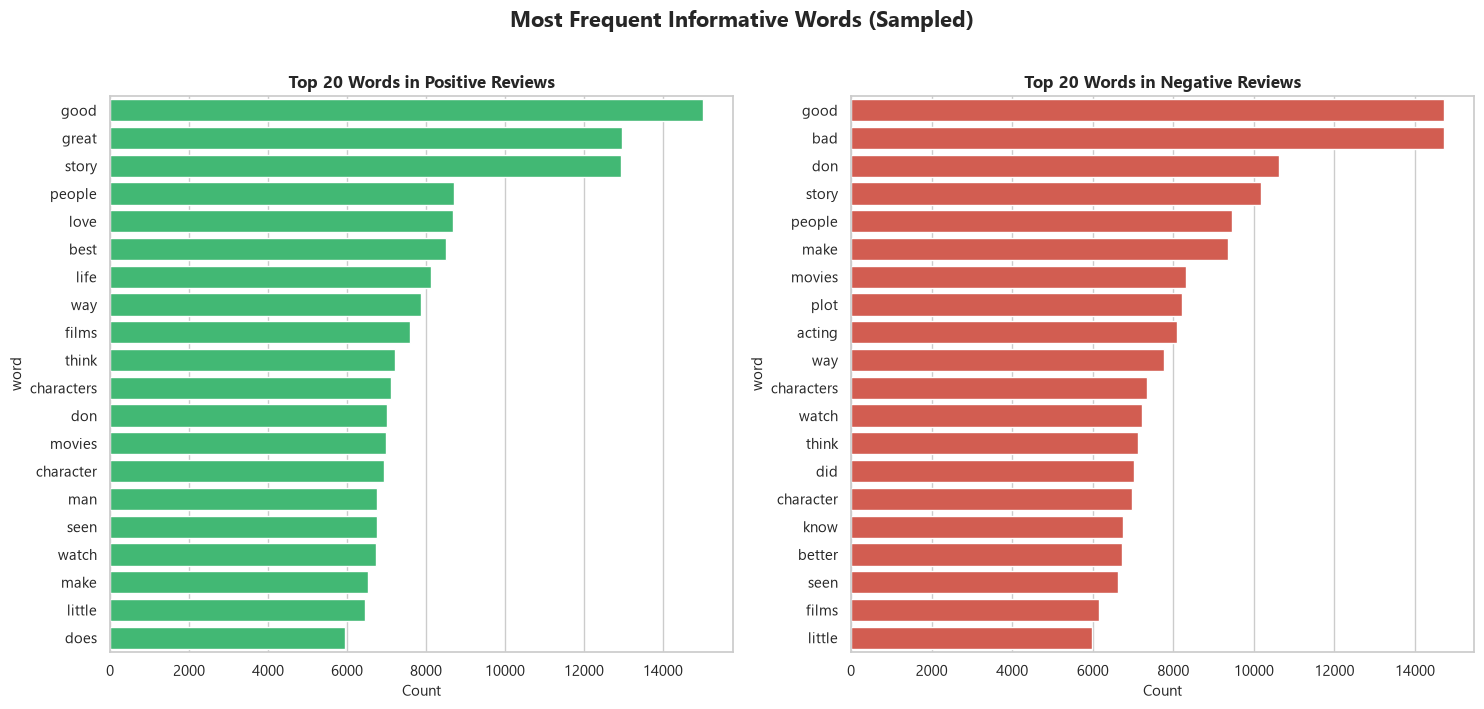

In [23]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

custom_stopwords = set(ENGLISH_STOP_WORDS).union({'br', 'film', 'movie', 'one', 'like', 'just', 'really', 'time'})

def clean_and_tokenize(text):
    # Remove HTML tags and non-alphabetical characters
    text = re.sub(r'<.*?>', ' ', text.lower())
    words = re.findall(r'\b[a-z]{3,}\b', text)
    return [w for w in words if w not in custom_stopwords]

# Sample 5,000 reviews from each class for rapid interactive plotting
sample_pos = df[df['sentiment'] == 'positive']['review'].sample(25000, random_state=42)
sample_neg = df[df['sentiment'] == 'negative']['review'].sample(25000, random_state=42)

pos_words = Counter([w for rev in sample_pos for w in clean_and_tokenize(rev)])
neg_words = Counter([w for rev in sample_neg for w in clean_and_tokenize(rev)])

# Plot top 20 words for each class
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7))

pos_df = pd.DataFrame(pos_words.most_common(20), columns=['word', 'count'])
neg_df = pd.DataFrame(neg_words.most_common(20), columns=['word', 'count'])

sns.barplot(data=pos_df, x='count', y='word', ax=ax1, color='#2ecc71')
ax1.set_title("Top 20 Words in Positive Reviews", fontweight="bold")
ax1.set_xlabel("Count")

sns.barplot(data=neg_df, x='count', y='word', ax=ax2, color='#e74c3c')
ax2.set_title("Top 20 Words in Negative Reviews", fontweight="bold")
ax2.set_xlabel("Count")

plt.suptitle("Most Frequent Informative Words (Sampled)", fontsize=16, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()


### very similar vocabulary
### the word 'good' appers in both, but the word 'bad' only appears in negetive reviews

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_20576\1157607289.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=pos_bigrams, x='count', y='ngram', ax=ax1, palette='Greens_r')
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_20576\1157607289.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=neg_bigrams, x='count', y='ngram', ax=ax2, palette='Reds_r')


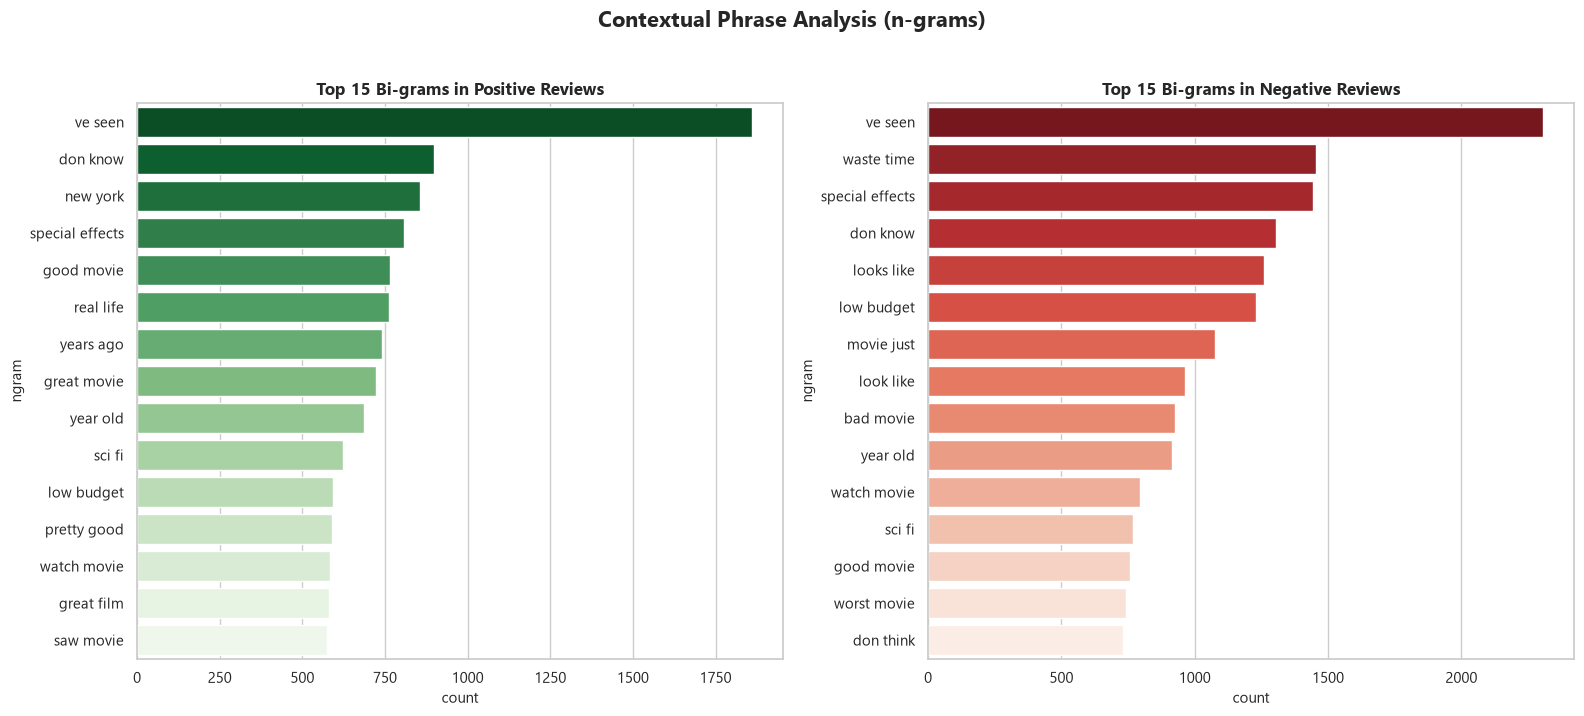

In [24]:
#visualize after cleaning the data

from sklearn.feature_extraction.text import CountVectorizer

def get_top_ngrams(corpus, n=2, top_k=15):
    vec = CountVectorizer(ngram_range=(n, n), stop_words='english').fit(corpus)
    bag_of_words = vec.transform(corpus)
    sum_words = bag_of_words.sum(axis=0) 
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)
    return pd.DataFrame(words_freq[:top_k], columns=['ngram', 'count'])

pos_bigrams = get_top_ngrams(sample_pos, n=2, top_k=15)
neg_bigrams = get_top_ngrams(sample_neg, n=2, top_k=15)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(data=pos_bigrams, x='count', y='ngram', ax=ax1, palette='Greens_r')
ax1.set_title("Top 15 Bi-grams in Positive Reviews", fontweight="bold")

sns.barplot(data=neg_bigrams, x='count', y='ngram', ax=ax2, palette='Reds_r')
ax2.set_title("Top 15 Bi-grams in Negative Reviews", fontweight="bold")

plt.suptitle("Contextual Phrase Analysis (n-grams)", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


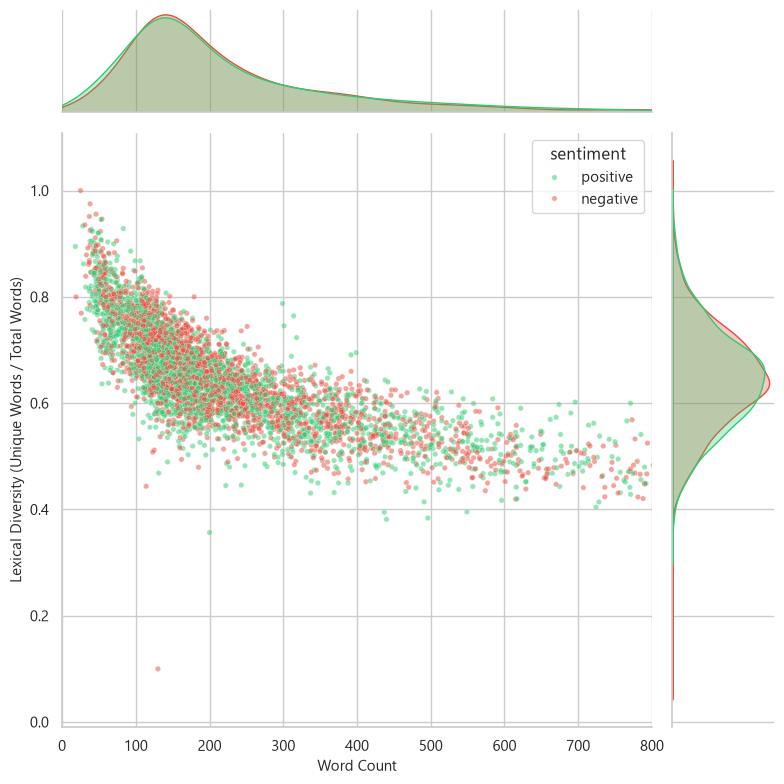

In [25]:
def lexical_diversity(text):
    words = text.lower().split()
    if len(words) == 0:
        return 0
    # Ratio of unique words to total words
    return len(set(words)) / len(words)

# Apply to a sample of the dataframe for performance
df_sample = df.sample(5000, random_state=42).copy()
df_sample['lexical_diversity'] = df_sample['review'].apply(lexical_diversity)

# Create a JointGrid to show the relationship between review length and diversity
g = sns.JointGrid(data=df_sample, x='word_count', y='lexical_diversity', hue='sentiment', 
                  height=8, palette={'positive': '#2ecc71', 'negative': '#e74c3c'})

# Add scatter plots in the center
g.plot_joint(sns.scatterplot, s=15, alpha=0.5)

# Add KDE density curves on the margins
g.plot_marginals(sns.kdeplot, fill=True, alpha=0.3)

g.ax_joint.set_title("Lexical Diversity vs. Review Length", fontweight="bold", pad=20)
g.ax_joint.set_xlabel("Word Count")
g.ax_joint.set_ylabel("Lexical Diversity (Unique Words / Total Words)")
# Limit X axis to exclude massive outliers for better visibility
g.ax_joint.set_xlim(0, 800) 

plt.show()
